In [1]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow_graphics.math.interpolation import bspline

In [ ]:
tfg_math

In [ ]:
tf.reset_default_graph()

x = [i for i in range(0,128,8)]
x.append(127)
x = np.asarray(x, np.float32)

y = np.asarray([np.sin(2*np.pi * t/128) for t in x], np.float32)
k = np.concatenate((np.reshape(x,(1,-1)),np.reshape(y,(1,-1))),0)
k = np.reshape(k, (1,k.shape[0], k.shape[1]))
p = np.asarray(np.reshape(np.arange(0,128),(1,1,-1)), np.float32) 
knots = tf.placeholder(dtype=tf.float32, shape=[None,2,17], name="control_points")
positions = tf.placeholder(dtype=tf.float32, shape=[None,1,128], name="positions")
spline_op = bspline.interpolate(knots=knots, positions=positions, degree=3, cyclical=False)

with tf.Session() as sess:
    z = sess.run(spline_op, feed_dict={knots:k, positions:p})
z = np.squeeze(z)

plt.plot(k[0,0,:], k[0,1,:], 'b.')
plt.plot(z[:,0], z[:,1], 'g')

In [41]:
x = np.linspace([0], [2*np.pi], 100).reshape(1,1,-1)
y = np.sin(x)

In [47]:
k = np.concatenate((x,y),1)
p = np.linspace([0], [2*np.pi], 100).reshape(1,1,-1)

In [49]:
Y = bspline.interpolate(
    knots=k,
    positions=p,
    degree=3,
    cyclical=False
)

In [50]:
Y = np.squeeze(Y)

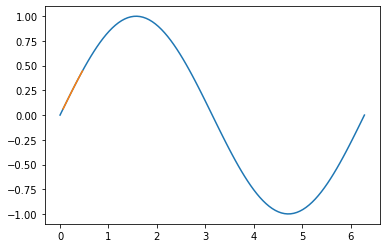

In [52]:

plt.plot(np.squeeze(x), np.squeeze(y))
plt.plot(Y.T[0], Y.T[1])

In [160]:
x = np.linspace([0], [2*np.pi], 1000)
y = np.sin(x)

In [161]:
cyclical = True
degree = 3
# Define knots
knots = np.concatenate((x,y),1).T
# Define positions
num_knots = knots.shape[1]
max_pos = num_knots #if cyclical else num_knots-degree
positions = np.linspace([0], [max_pos], 1000)

In [162]:
print(positions.shape)
print(knots.shape)

(1000, 1)
(2, 1000)


In [163]:
spline = bspline.interpolate(knots, positions, degree, cyclical)
spline = tf.squeeze(spline)

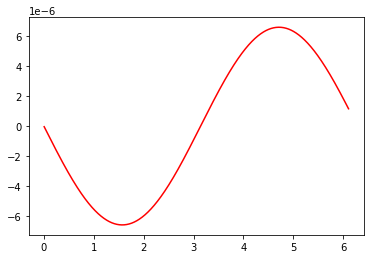

In [164]:
X = spline[:970, 0]
Y = np.sin(X)
plt.figure()
plt.plot(X, spline[:970, 1] - Y, 'r')
# plt.plot(knots[0, :], knots[1, :], 'b.')
plt.show()

In [53]:


cyclical = True
degree = 3



#@title B-Spline Interpolation { vertical-output: true, run: "auto"}

num_knots = 5
cyclical = True  #@param { type: "boolean" }
degree = 3  #@param { type: "slider", min: 1, max: 4, step: 1}
knot_1_x = -2.5  #@param { type: "slider", min: -3.0, max: 3.0, step: 0.5}
knot_1_y = -1  #@param { type: "slider", min: -3.0, max: 3.0, step: 0.5}
knot_2_x = -1.5  #@param { type: "slider", min: -3.0, max: 3.0, step: 0.5}
knot_2_y = 2  #@param { type: "slider", min: -3.0, max: 3.0, step: 0.5}
knot_3_x = 0  #@param { type: "slider", min: -3.0, max: 3.0, step: 0.5}
knot_3_y = -3  #@param { type: "slider", min: -3.0, max: 3.0, step: 0.5}
knot_4_x = 1.5  #@param { type: "slider", min: -3.0, max: 3.0, step: 0.5}
knot_4_y = 3  #@param { type: "slider", min: -3.0, max: 3.0, step: 0.5}
knot_5_x = 3  #@param { type: "slider", min: -3.0, max: 3.0, step: 0.5}
knot_5_y = 0  #@param { type: "slider", min: -3.0, max: 3.0, step: 0.5}

max_pos = num_knots if cyclical else num_knots - degree
knots = tf.constant(((knot_1_x, knot_2_x, knot_3_x, knot_4_x, knot_5_x),
                     (knot_1_y, knot_2_y, knot_3_y, knot_4_y, knot_5_y)))

positions = tf.expand_dims(
    tf.range(start=0.0, limit=max_pos, delta=0.01, dtype=knots.dtype), axis=-1)


In [59]:
print(positions.shape)
print(knots.shape)
max_pos

(500, 1)
(2, 5)


5

In [61]:

p = np.linspace([0], [2*np.pi], 100)
p.shape

(100, 1)

In [ ]:

spline = bspline.interpolate(knots, positions, degree, cyclical)
spline = tf.squeeze(spline, axis=1)

plt.figure(figsize=(10, 10))
plt.plot(spline[:, 0], spline[:, 1], 'r')
plt.plot(knots[0, :], knots[1, :], 'b.')
plt.axis((-3.5, 3.5, -3.5, 3.5))
plt.show()

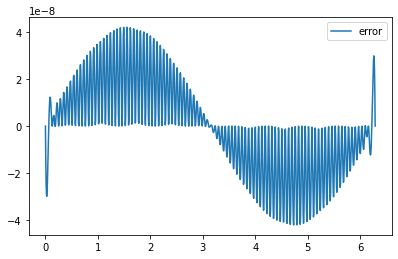

In [168]:
from scipy.interpolate import CubicSpline, UnivariateSpline

import matplotlib.pyplot as plt



x = np.linspace(0, 2*np.pi, 100)

y = np.sin(x)

cs = CubicSpline(x, y)

p = np.linspace(0, 2*np.pi, 1000)

fig, ax = plt.subplots(figsize=(6.5, 4))

# ax.plot(x, y, 'o', label='data')

ax.plot(p, np.sin(p) - cs(p), label='error')

# ax.plot(p, cs(p), label="S")


ax.legend()

plt.show()

In [158]:
import numpy as np
from scipy.interpolate import RectBivariateSpline
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# Regularly-spaced, coarse grid
dx, dy = 0.1, 0.5
xmax, ymax = 2, 4
x = np.arange(-xmax, xmax, dx)
y = np.arange(-ymax, ymax, dy)
X, Y = np.meshgrid(x, y)
Z = np.exp(-(2*X)**2 - (Y/2)**2)


interp_spline = RectBivariateSpline(y, x, Z)

# Regularly-spaced, fine grid
dx2, dy2 = 0.5, 0.5
x2 = np.arange(-xmax, xmax, dx2)
y2 = np.arange(-ymax, ymax, dy2)
X2, Y2 = np.meshgrid(x2,y2)
Z2 = interp_spline(y2, x2)



Z2_ = np.exp(-(2*X2)**2 - (Y2/2)**2)

err = np.amax(np.abs(Z2_ - Z2))
print(err)
# fig, ax = plt.subplots(nrows=1, ncols=2, subplot_kw={'projection': '3d'})
# ax[0].plot_wireframe(X, Y, Z, color='k')

# ax[1].plot_wireframe(X2, Y2, Z2, color='k')
# for axes in ax:
#     axes.set_zlim(-0.2,1)
#     axes.set_axis_off()

# fig.tight_layout()
# plt.show()


2.7755575615628914e-16


In [159]:
interp_spline.get_coeffs()

array([ 2.06115362e-09,  8.53552023e-04, -1.86579507e-03,  3.83152900e-03,
        2.55430301e-02, -3.32743125e-03,  6.49589049e-04,  2.26032941e-06,
        3.47218388e-09,  1.43787903e-03, -3.14308624e-03,  6.45452774e-03,
        4.30293484e-02, -5.60533336e-03,  1.09428652e-03,  3.80771198e-06,
        7.14785599e-09,  2.96002533e-03, -6.47037384e-03,  1.32873247e-02,
        8.85804428e-02, -1.15391687e-02,  2.25270398e-03,  7.83857589e-06,
        2.25128725e-08,  9.32288969e-03, -2.03790761e-02,  4.18497306e-02,
        2.78992780e-01, -3.63437420e-02,  7.09511182e-03,  2.46883625e-05,
        4.04913243e-08,  1.67680135e-02, -3.66535092e-02,  7.52703154e-02,
        5.01792347e-01, -6.53673246e-02,  1.27611647e-02,  4.44041289e-05,
        6.39180934e-08,  2.64693603e-02, -5.78598617e-02,  1.18818911e-01,
        7.92110672e-01, -1.03186419e-01,  2.01442983e-02,  7.00947006e-05,
        8.85599606e-08,  3.66738960e-02, -8.01661440e-02,  1.64626282e-01,
        1.09748721e+00, -